## WORKSHOP NO: 01 ADDING SUNGLASS TO YOUR PASSPORT PHOTO USING OPENCV

## NAME: SYED SHAMSHEER ALI.B

## REG.NO: 212225220114

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

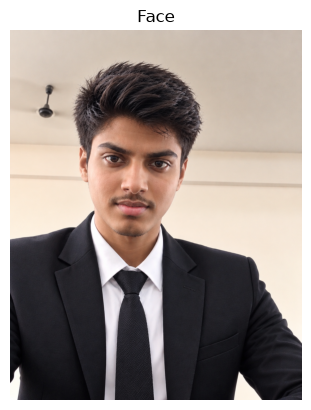

In [2]:
img = cv2.imread(r'C:\Users\syedf\OneDrive\Documents\DIPT\Syed1.png')
if img is not None:
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Face")
    plt.axis('off')
    plt.show()
else:
    print("Image not found!")

In [3]:
print(img.shape)
faceImage = cv2.imread(r'C:\Users\syedf\OneDrive\Documents\DIPT\Syed1.png')
print(faceImage.shape if faceImage is not None else "Image not found!")

(1412, 1114, 3)
(1412, 1114, 3)


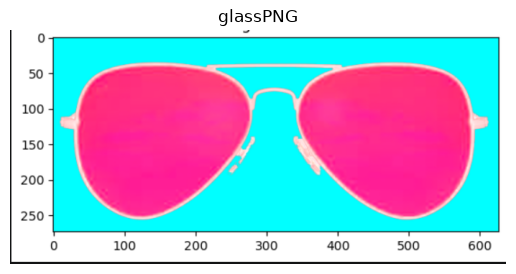

In [4]:
glassPNG = cv2.imread(r'C:\Users\syedf\OneDrive\Documents\DIPT\sunglass.png', -1)
if glassPNG is not None:
    plt.imshow(cv2.cvtColor(glassPNG, cv2.COLOR_BGRA2RGBA));
    plt.title("glassPNG"); 
    plt.axis('off'); 
    plt.show()
else:
    print("Image not found!")

In [5]:
glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(50, 190, 4)


In [6]:
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

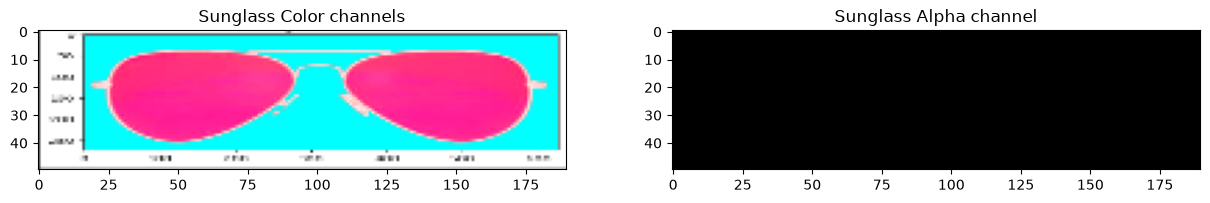

In [7]:
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

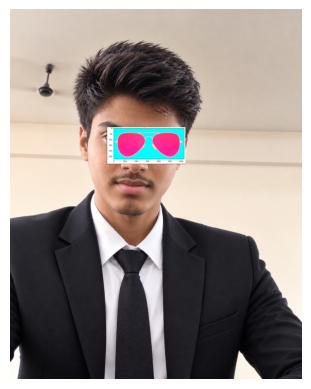

In [8]:
img = cv2.imread(r'C:\Users\syedf\OneDrive\Documents\DIPT\Syed1.png')
glassPNG = cv2.imread(r'C:\Users\syedf\OneDrive\Documents\DIPT\sunglass.png', -1)

w = 300; h = int(glassPNG.shape[0]*w/glassPNG.shape[1])
glass = cv2.resize(glassPNG, (w, h))
x, y = 370, 450
roi = img[y:y+h, x:x+w]; a = glass[:,:,3:4]/255
img[y:y+h, x:x+w] = (glass[:,:,:3]*a + roi*(1-a)).astype('uint8')

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

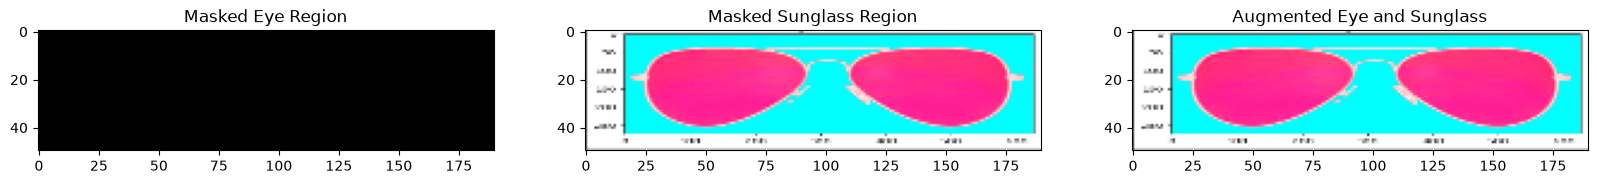

In [9]:
glassMask = np.uint8(cv2.merge((glassMask1,)*3)/255)
faceWithGlassesArithmetic = faceImage.copy()
eyeROI = faceWithGlassesArithmetic[135:185,110:300]
maskedEye = cv2.multiply(eyeROI, 1-glassMask)
maskedGlass = cv2.multiply(glassBGR, glassMask)
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

plt.figure(figsize=[20,20])
for i,(im,t) in enumerate([(maskedEye,"Masked Eye Region"),(maskedGlass,"Masked Sunglass Region"),(eyeRoiFinal,"Augmented Eye and Sunglass")],1):
    plt.subplot(1,3,i); plt.imshow(im[...,::-1]); plt.title(t)

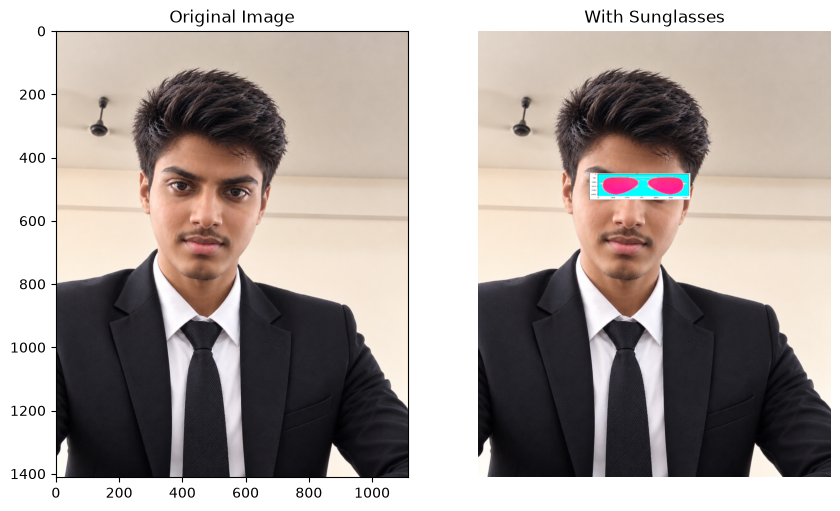

In [10]:
faceWithGlassesArithmetic[135:185,110:300] = eyeRoiFinal
plt.figure(figsize=[10,10])
plt.subplot(121); plt.imshow(faceImage[:,:,::-1]); plt.title("Original Image")
plt.subplot(122); plt.imshow(faceWithGlassesArithmetic[:,:,::-1]); plt.title("With Sunglasses")

w=320; h=int(glassBGR.shape[0]*w/glassBGR.shape[1])
glass=cv2.resize(glassBGR,(w,h))
mask=cv2.merge([cv2.resize(glassMask1,(w,h),interpolation=cv2.INTER_NEAREST).astype(np.float32)/255]*3)
x,y=350,450; out=faceImage.copy(); roi=out[y:y+h,x:x+w]
out[y:y+h,x:x+w]=(roi*(1-mask)+glass*mask).astype(np.uint8)

plt.imshow(cv2.cvtColor(out,cv2.COLOR_BGR2RGB)); plt.title("With Sunglasses"); plt.axis('off'); plt.show()